# Практикум: тест ABBA-BABA (D-статистика) и поиск интрогрессии у бабочек *Heliconius*

**Курс:** Популяционная генетика  
**Инструменты:** Python-скрипты [genomics_general](https://github.com/simonhmartin/genomics_general), R  
**Основа:** туториал Simon Martin — [ABBA_BABA_whole_genome](https://github.com/simonhmartin/tutorials/tree/master/ABBA_BABA_whole_genome)

Статистики ABBA-BABA (D-статистики; Green et al., 2010; Durand et al., 2011) — простой и эффективный тест на отклонение от строго бифуркационной (древовидной) эволюционной истории. Их широко используют для выявления **интрогрессии** — обмена генами между видами — по полногеномным SNP-данным (полногеномное секвенирование, RADseq и др.).

В этом практикуме мы проведём анализ ABBA-BABA на геномных данных нескольких популяций бабочек рода *Heliconius* (Martin et al., 2013).

**План анализа:** оцениваем частоты производных аллелей в каждой популяции → вычисляем D-статистику → проверяем её отличие от нуля методом block jackknife → оцениваем долю примеси *f* → повторяем анализ по отдельным хромосомам.

### Содержание
1. Подготовка окружения и данных
2. Частоты производных аллелей
3. D-статистика
4. Значимость D: block jackknife
5. Доля примеси *f*
6. D-статистика по хромосомам
7. Вопросы для обсуждения
8. Домашнее задание


В этой практике нужно изучить несколько рас трёх видов: Heliconius melpomene, Heliconius timareta и Heliconius cydno. Ареалы этих видов частично перекрываются, и считается, что в зонах симпатрии происходит гибридизация между ними. В выборке есть две пары симпатрических рас H. melpomene и H. cydno из Панамы и с западных склонов Анд в Колумбии. Есть также две пары симпатрических рас H. melpomene и H. timareta с восточных склонов Анд в Колумбии и Перу. Наконец, в выборку входят два образца внешней группы — вида Heliconius numata: они необходимы для анализа ABBA-BABA.

Все образцы секвенированы методом полногеномного секвенирования с высоким покрытием. Данные отфильтрованы: оставлены только биаллельные однонуклеотидные полиморфизмы (SNP). Затем их дополнительно проредили, чтобы уменьшить размер файла для этого практикума.

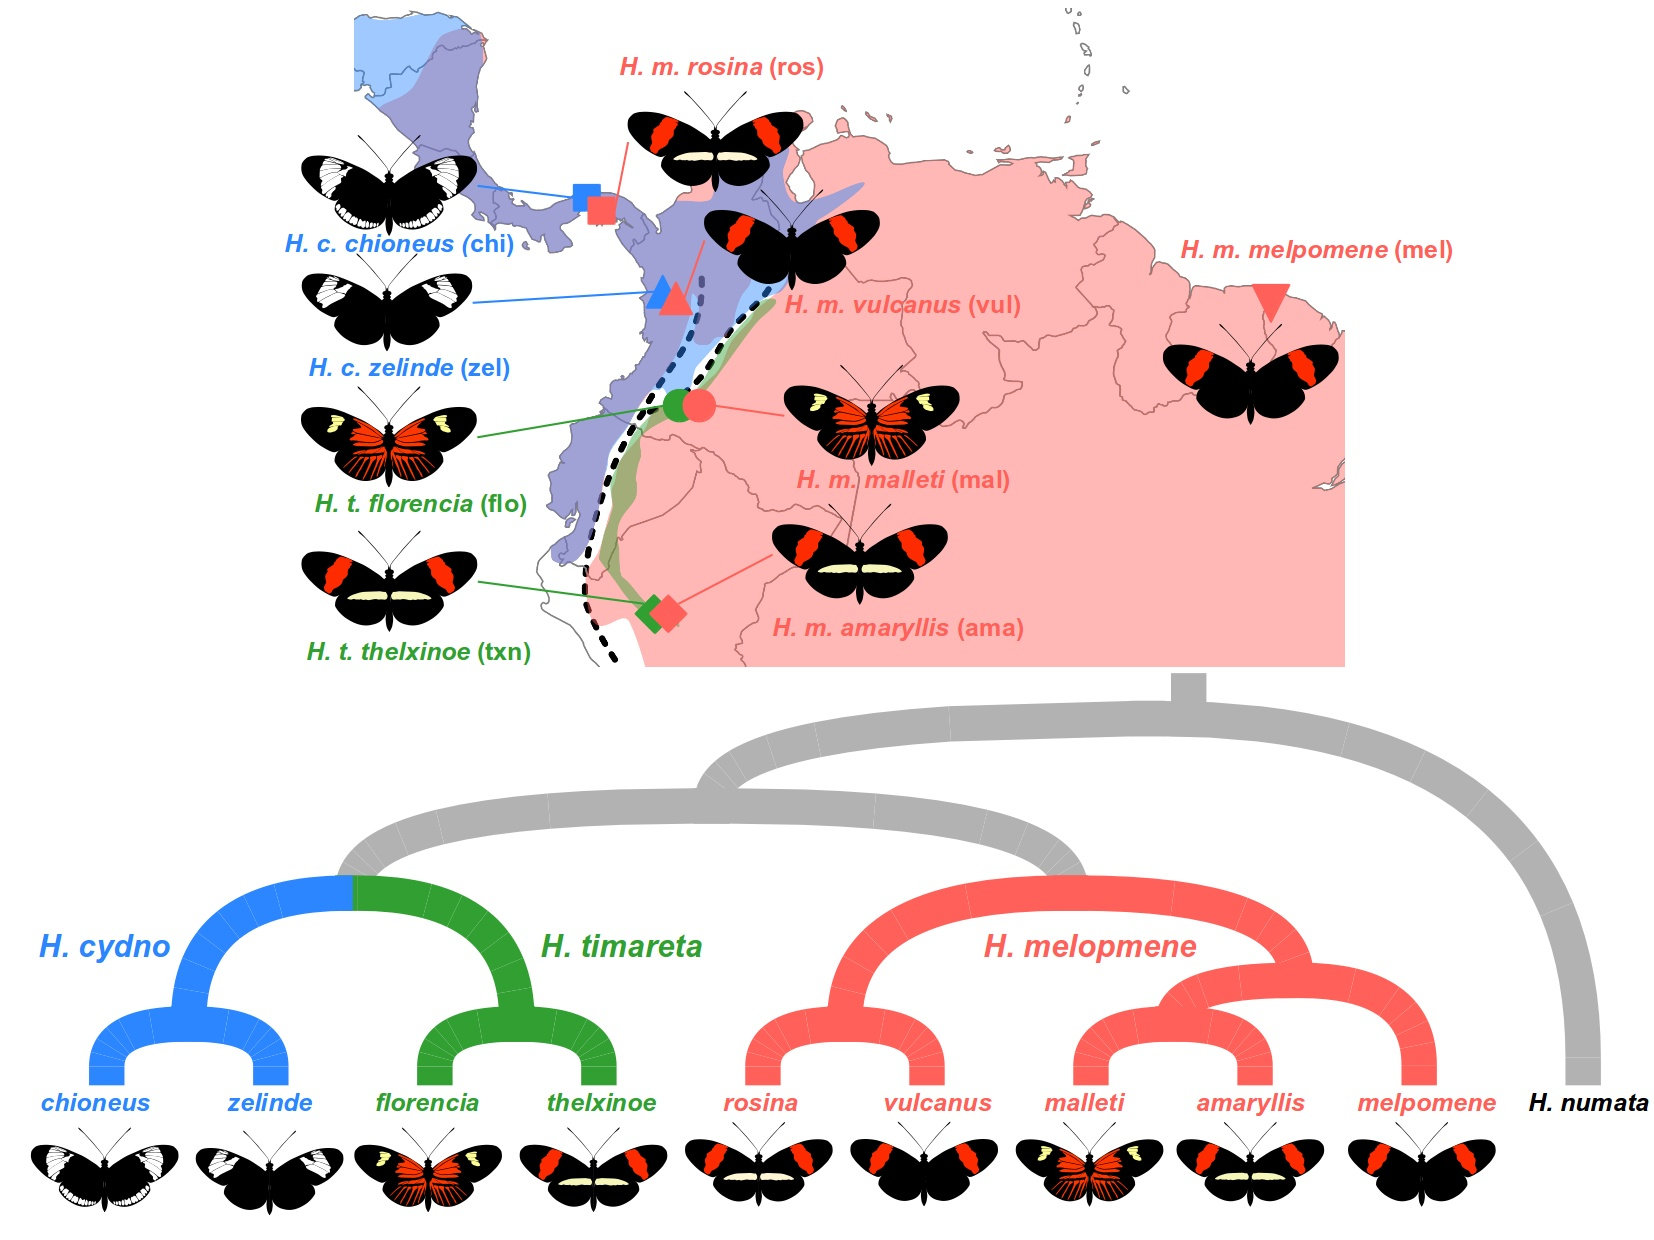

**Гипотезы**

Мы предполагаем, что гибридизация видов в зонах симпатрии приводит к обмену генетической изменчивостью между H. cydno и симпатрическими с ним расами H. melpomene к западу от Анд, а также между H. timareta и соответствующими симпатрическими расами H. melpomene к востоку от Анд.

В выборке есть ещё одна раса H. melpomene — из Французской Гвианы. Она аллопатрична и H. timareta, и H. cydno, поэтому не должна была в недавнем прошлом обмениваться генами ни с одним из этих видов и служит контролем.

Помимо проверки самого факта интрогрессии, мы проверим гипотезу о том, что одни участки генома подвержены интрогрессии сильнее, чем другие. Известно, что по крайней мере один локус на половой Z-хромосоме вызывает стерильность самок-гибридов между этими видами. Это указывает на несовместимость между аутосомами одного вида и Z-хромосомой другого. Поэтому можно ожидать, что на Z-хромосоме интрогрессия будет слабее, чем на аутосомах.

*Популяции Heliconius в анализе: ареалы (вверху) и филогения (внизу). Голубым показан H. cydno, зелёным — H. timareta, красным — H. melpomene; H. numata — внешняя группа.*

| Код | Таксон | Вид |
|---|---|---|
| `mel_mel` | *H. m. melpomene* | *H. melpomene* |
| `mel_ros` | *H. m. rosina* | *H. melpomene* |
| `mel_vul` | *H. m. vulcanus* | *H. melpomene* |
| `mel_mal` | *H. m. malleti* | *H. melpomene* |
| `mel_ama` | *H. m. amaryllis* | *H. melpomene* |
| `cyd_chi` | *H. c. chioneus* | *H. cydno* |
| `cyd_zel` | *H. c. zelinde* | *H. cydno* |
| `tim_flo` | *H. t. florencia* | *H. timareta* |
| `tim_txn` | *H. t. thelxinoe* | *H. timareta* |
| `num` | *H. numata* | внешняя группа |

## 1. Подготовка окружения и данных

### 1.1. Загрузка данных

- `hel92.DP8MP4BIMAC2HET75dist250.geno.gz` — генотипы 92 особей (уже отфильтрованы, только **биаллельные** сайты);
- `hel92.pop.txt` — соответствие особей популяциям.

In [ ]:
!mkdir -p data
!wget -q -P data https://github.com/simonhmartin/tutorials/raw/master/ABBA_BABA_whole_genome/data/hel92.DP8MP4BIMAC2HET75dist250.geno.gz
!wget -q -P data https://github.com/simonhmartin/tutorials/raw/master/ABBA_BABA_whole_genome/data/hel92.pop.txt
!ls -lh data

### 1.2. Скрипты genomics_general

In [ ]:
!wget -q https://github.com/simonhmartin/genomics_general/archive/master.zip
!unzip -q -o master.zip
!ls genomics_general-master

**Исправление совместимости с NumPy 2.0.** В `genomics.py` используется константа `np.NaN`, удалённая в NumPy 2.0 (в Colab сейчас стоит NumPy 2.x). Без этой замены `freq.py` завершится ошибкой `AttributeError`.

In [ ]:
!sed -i 's/np\.NaN/np.nan/g' genomics_general-master/genomics.py

### 1.3. Состав популяций

In [ ]:
!head data/hel92.pop.txt
!echo "Число особей:"
!wc -l < data/hel92.pop.txt

In [ ]:
# Число особей в каждой популяции
!cut -f2 data/hel92.pop.txt | sort | uniq -c

## 2. Частоты производных аллелей

Для каждого полиморфного сайта нужно определить частоту **производного** (derived) аллеля в каждой популяции. Это делает скрипт `freq.py`; состав популяций берётся из `hel92.pop.txt`.

С флагом `--target derived` скрипт считает частоту производного аллеля, используя **последнюю** указанную популяцию (*H. numata*, `num`) как внешнюю группу. Сайты, где внешняя группа не фиксирована по предковому аллелю, отбрасываются.

In [ ]:
# Справка по параметрам скрипта
!python genomics_general-master/freq.py -h

In [ ]:
!python genomics_general-master/freq.py \
    -g data/hel92.DP8MP4BIMAC2HET75dist250.geno.gz \
    -p mel_mel -p mel_ros -p mel_vul -p mel_mal -p mel_ama \
    -p cyd_chi -p cyd_zel -p tim_flo -p tim_txn -p num \
    --popsFile data/hel92.pop.txt \
    --target derived \
    -o data/hel92.DP8MP4BIMAC2HET75dist250.derFreq.tsv.gz


Starting 1 worker threads
14 slices queued | 13 slices analysed | 13 slices written | 29052 lines written
29 slices queued | 28 slices analysed | 28 slices written | 62337 lines written
43 slices queued | 42 slices analysed | 42 slices written | 93713 lines written
56 slices queued | 55 slices analysed | 55 slices written | 122893 lines written
71 slices queued | 70 slices analysed | 70 slices written | 156755 lines written
86 slices queued | 85 slices analysed | 85 slices written | 190372 lines written
100 slices queued | 99 slices analysed | 99 slices written | 221414 lines written
114 slices queued | 113 slices analysed | 113 slices written | 252735 lines written
129 slices queued | 128 slices analysed | 128 slices written | 286452 lines written
144 slices queued | 143 slices analysed | 143 slices written | 319820 lines written
158 slices queued | 157 slices analysed | 156 slices written | 349833 lines written
171 slices queued | 170 slices analysed | 170 slices written | 380075 li

## 3. D-статистика

Рассмотрим четыре таксона с топологией (((P1, P2), P3), O), где O — внешняя группа, несущая предковый аллель **A**, а **B** — производный аллель. Паттерн **ABBA** означает, что P2 и P3 делят производный аллель, **BABA** — что его делят P1 и P3.

При неполной сортировке линий (ILS) без потока генов оба паттерна равновероятны, и D ≈ 0. Избыток ABBA (D > 0) указывает на поток генов между P3 и P2, избыток BABA (D < 0) — между P3 и P1.

Для популяционных данных паттерны считаются через частоты производного аллеля $\hat p$ в каждом сайте $i$ (внешняя группа фиксирована по предковому аллелю):

$$\mathrm{ABBA}_i = (1-\hat p_{i1})\,\hat p_{i2}\,\hat p_{i3}, \qquad \mathrm{BABA}_i = \hat p_{i1}\,(1-\hat p_{i2})\,\hat p_{i3}$$

$$D = \frac{\sum_i \mathrm{ABBA}_i - \sum_i \mathrm{BABA}_i}{\sum_i \mathrm{ABBA}_i + \sum_i \mathrm{BABA}_i}$$

D меняется от −1 до 1.

In [ ]:
# Подключение R к Python-ноутбуку (в Colab rpy2 обычно уже установлен)
!pip install -q rpy2
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
# D-статистика по частотам производного аллеля в P1, P2, P3
D.stat <- function(p1, p2, p3) {
  ABBA <- (1 - p1) * p2 * p3
  BABA <- p1 * (1 - p2) * p3
  (sum(ABBA, na.rm = TRUE) - sum(BABA, na.rm = TRUE)) /
    (sum(ABBA, na.rm = TRUE) + sum(BABA, na.rm = TRUE))
}

In [ ]:
%%R
freq_table <- read.table("data/hel92.DP8MP4BIMAC2HET75dist250.derFreq.tsv.gz",
                         header = TRUE, as.is = TRUE)
cat("Число сайтов:", nrow(freq_table), "\n")
head(freq_table)

Число сайтов: 752882 
  scaffold position mel_mel mel_ros mel_vul mel_mal mel_ama cyd_chi cyd_zel
1     chr1      765       0       0       0  0.0000  0.0000  0.0000  0.1000
2     chr1     1018       0       0       0  0.2500  0.0000  0.0000  0.0000
3     chr1     1273       0       0       0  0.0000  0.0000  0.0000  0.1111
4     chr1     1532       0       0       0  0.0000  0.0000  0.1000  0.0500
5     chr1     1782       1       1       1  1.0000  0.3000  1.0000  1.0000
6     chr1     2041       0       0       0  0.3125  0.8333  0.0833  0.0000
  tim_flo tim_txn num
1       0    0.00   0
2       0    0.00   0
3       0    0.00   0
4       0    0.05   0
5       1    0.85   0
6       0    0.00   0


Выберем тройку популяций: аллопатрический *H. m. melpomene* из Французской Гвианы (P1), симпатрический с *H. cydno* *H. m. rosina* из Панамы (P2) и *H. c. chioneus* из Панамы (P3). Если в зоне симпатрии идёт гибридизация, ожидаем избыток паттерна ABBA.

In [ ]:
%%R
P1 <- "mel_mel"
P2 <- "mel_ros"
P3 <- "cyd_chi"

D <- D.stat(freq_table[, P1], freq_table[, P2], freq_table[, P3])
cat("D =", round(D, 4), "\n")

D = 0.3821 


Ожидаемый результат: D ≈ 0.38. Это выраженное положительное значение, то есть паттерны ABBA преобладают над BABA. Значит, *H. c. chioneus* из Панамы делит больше генетической изменчивости с симпатрическим *H. m. rosina*, чем с аллопатрическим *H. m. melpomene*. Результат согласуется с гибридизацией и обменом генами между видами в зоне симпатрии.

## 4. Значимость D: block jackknife

Соседние SNP сцеплены и не являются независимыми наблюдениями, поэтому обычные формулы для стандартной ошибки здесь не подходят. Метод **block jackknife** делит геном на блоки, поочерёдно исключает каждый блок и пересчитывает D; разброс полученных значений даёт оценку стандартной ошибки.

Размер блока должен превышать расстояние, на котором сохраняется сцепление. Используем блоки по 1 Мб: известно, что неравновесие по сцеплению у *Heliconius* спадает до фонового уровня на значительно меньших расстояниях.

In [ ]:
%%R
source("genomics_general-master/jackknife.R")

block_indices <- get.block.indices(block_size  = 1e6,
                                   positions   = freq_table$position,
                                   chromosomes = freq_table$scaffold)
cat("Геном разделён на", length(block_indices), "блоков\n")

Геном разделён на 284 блоков


In [ ]:
%%R
D_jackknife <- block.jackknife(block_indices = block_indices,
                               FUN = D.stat,
                               freq_table[, P1], freq_table[, P2], freq_table[, P3])
cat("Среднее D по jackknife =", round(D_jackknife$mean, 4), "\n")

Среднее D по jackknife = 0.3821 


Зная среднее и стандартную ошибку D, вычисляем Z-оценку:

$$Z = \frac{D}{SE(D)}$$

Обычно |Z| > 3 считается значимым отклонением от нуля.

In [ ]:
%%R
D_Z <- D_jackknife$mean / D_jackknife$standard_error
cat("Z =", round(D_Z, 3), "\n")

Z = 40.008 


Ожидаемый результат: Z ≈ 40. Отклонение D от нуля крайне значимо.

## 5. Доля примеси *f*

D-статистика показывает **наличие** интрогрессии, но плохо оценивает её **величину**. Для оценки доли примеси (admixture proportion) используют статистику *f* (Green et al., 2010; Durand et al., 2011). Популяцию-донора P3 делят на две части, P3a и P3b. Знаменатель — ожидаемый избыток ABBA при **полном** смешении, когда P2 заменена на P3b:

$$S(P_1, P_2, P_3) = \sum_i \mathrm{ABBA}_i - \sum_i \mathrm{BABA}_i$$

$$\hat f = \frac{S(P_1, P_2, P_{3a})}{S(P_1, P_{3b}, P_{3a})}$$

In [ ]:
%%R
f.stat <- function(p1, p2, p3a, p3b) {
  # Наблюдаемый избыток ABBA
  ABBA_numerator <- (1 - p1) * p2 * p3a
  BABA_numerator <- p1 * (1 - p2) * p3a
  # Ожидаемый избыток ABBA при полном смешении (P2 заменена на P3b)
  ABBA_denominator <- (1 - p1) * p3b * p3a
  BABA_denominator <- p1 * (1 - p3b) * p3a

  (sum(ABBA_numerator, na.rm = TRUE) - sum(BABA_numerator, na.rm = TRUE)) /
    (sum(ABBA_denominator, na.rm = TRUE) - sum(BABA_denominator, na.rm = TRUE))
}

В качестве P3a и P3b возьмём две популяции *H. cydno*: *H. c. chioneus* и *H. c. zelinde*.

In [ ]:
%%R
P3a <- "cyd_chi"
P3b <- "cyd_zel"

f <- f.stat(freq_table[, P1], freq_table[, P2], freq_table[, P3a], freq_table[, P3b])
cat("Доля примеси f =", round(f, 4), "\n")

Доля примеси f = 0.2743 


Ожидаемый результат: *f* ≈ 0.27, то есть в зоне симпатрии между *H. melpomene* и *H. cydno* было обменено около четверти генома. Долю примеси можно интерпретировать как среднюю долю чужеродной предковой компоненты в геноме или как ожидаемую частоту чужеродных аллелей в популяции в произвольном сайте генома.

Снова применим block jackknife, чтобы получить доверительный интервал для *f*. Индексы блоков уже рассчитаны, поэтому достаточно передать функции jackknife `f.stat` вместо `D.stat`.

In [ ]:
%%R
f_jackknife <- block.jackknife(block_indices = block_indices,
                               FUN = f.stat,
                               freq_table[, P1], freq_table[, P2],
                               freq_table[, P3a], freq_table[, P3b])

f_CI_lower <- f_jackknife$mean - 1.96 * f_jackknife$standard_error
f_CI_upper <- f_jackknife$mean + 1.96 * f_jackknife$standard_error
cat("95% доверительный интервал f:", round(f_CI_lower, 4), "-", round(f_CI_upper, 4), "\n")

## 6. D-статистика по хромосомам

Повторим анализ для каждой хромосомы отдельно, чтобы оценить интрогрессию по хромосомам (при условии, что SNP на каждой хромосоме достаточно).

Сначала получаем названия всех хромосом функцией `unique()`. Затем для каждой хромосомы определяем номера строк таблицы, которые к ней относятся: `lapply()` применяет функцию к каждому названию хромосомы, а `which()` находит соответствующие строки в столбце `scaffold`. Результат — список из 21 элемента, по одному на хромосому.

In [ ]:
%%R
chrom_names   <- unique(freq_table$scaffold)
chrom_indices <- lapply(chrom_names, function(chrom) which(freq_table$scaffold == chrom))
names(chrom_indices) <- chrom_names

# Число SNP на каждой хромосоме
sapply(chrom_indices, length)

 chr1  chr2  chr3  chr4  chr5  chr6  chr7  chr8  chr9 chr10 chr11 chr12 chr13 
49289 23600 28864 26539 27549 38808 40185 25334 24094 50995 32731 45799 49678 
chr14 chr15 chr16 chr17 chr18 chr19 chr20 chr21 
25027 27208 27951 41179 47420 45644 41718 33270 


Значение D для каждой хромосомы:

In [ ]:
%%R
D_by_chrom <- sapply(chrom_names, function(chrom)
  D.stat(freq_table[chrom_indices[[chrom]], P1],
         freq_table[chrom_indices[[chrom]], P2],
         freq_table[chrom_indices[[chrom]], P3]))
round(D_by_chrom, 3)

  chr1   chr2   chr3   chr4   chr5   chr6   chr7   chr8   chr9  chr10  chr11 
 0.456  0.335  0.381  0.424  0.418  0.387  0.446  0.406  0.453  0.436  0.445 
 chr12  chr13  chr14  chr15  chr16  chr17  chr18  chr19  chr20  chr21 
 0.392  0.401  0.416  0.290  0.329  0.344  0.418  0.304  0.354 -0.088 


Для jackknife нужны блоки внутри каждой хромосомы. Получим список из 21 элемента, каждый из которых — список индексов блоков на соответствующей хромосоме. Проверим число блоков на хромосому и число SNP в каждом блоке.

In [ ]:
%%R
block_indices_by_chrom <- sapply(chrom_names, function(chrom)
  get.block.indices(block_size = 1e6,
                    positions  = freq_table$position[freq_table$scaffold == chrom]),
  simplify = FALSE)

cat("Число блоков на хромосому:\n")
print(sapply(block_indices_by_chrom, length))

In [ ]:
%%R
# Число SNP в каждом блоке
lapply(block_indices_by_chrom, sapply, length)

In [ ]:
%%R
D_jackknife_by_chrom <- sapply(chrom_names, function(chrom)
  block.jackknife(block_indices = block_indices_by_chrom[[chrom]],
                  FUN = D.stat,
                  freq_table[chrom_indices[[chrom]], P1],
                  freq_table[chrom_indices[[chrom]], P2],
                  freq_table[chrom_indices[[chrom]], P3]))

D_jackknife_by_chrom   <- as.data.frame(t(D_jackknife_by_chrom))
D_jackknife_by_chrom$Z <- as.numeric(D_jackknife_by_chrom$mean) /
                          as.numeric(D_jackknife_by_chrom$standard_error)
D_jackknife_by_chrom

Ожидаемый результат: хромосомы 1–20 показывают значимые признаки интрогрессии (Z > 4), а хромосома 21 — Z-хромосома — такого сигнала не даёт. Это говорит о сильном снижении интрогрессии на Z-хромосоме по сравнению с аутосомами и согласуется с отбором против интрогрессированных аллелей на половой хромосоме. Именно этого следует ожидать, если с Z-хромосомой связаны одна или несколько генетических несовместимостей, вызывающих стерильность гибридов (правило Холдейна: у бабочек гетерогаметны самки, ZW).

## 7. Вопросы для обсуждения

1. Какое значение D вы ожидаете, если взять в качестве P1 и P2 две аллопатрические по отношению к *H. cydno* популяции *H. melpomene*? Проверьте.
2. Почему для оценки величины интрогрессии используют *f*, а не D?
3. Почему размер блока для jackknife должен превышать масштаб LD? Что произойдёт с Z, если взять блоки по 10 кб?
4. Какие процессы, кроме интрогрессии, могут дать D ≠ 0?

### Литература

- Green R. E. et al. (2010) A draft sequence of the Neandertal genome. *Science* 328: 710–722.
- Durand E. Y., Patterson N., Reich D., Slatkin M. (2011) Testing for ancient admixture between closely related populations. *Mol. Biol. Evol.* 28: 2239–2252.
- Martin S. H. et al. (2013) Genome-wide evidence for speciation with gene flow in *Heliconius* butterflies. *Genome Research* 23: 1817–1828.

## 8. Домашнее задание (5 баллов, сдать до 15.11)

Ответы пишите в текстовых ячейках после каждого задания. Сдаётся этот ноутбук с выполненными ячейками. Все нужные функции и частоты аллелей уже есть в ноутбуке: частоты посчитаны для всех 10 популяций.

**Задание 1 (2 балла).** Посчитайте D, Z и долю примеси f для тройки P1 = `mel_mel`, P2 = `mel_mal`, P3 = `tim_flo` (для f: P3a = `tim_flo`, P3b = `tim_txn`). *H. m. malleti* и *H. t. florencia* живут рядом. Есть ли признаки интрогрессии? Сравните с парой *rosina* – *chioneus* с занятия.

**Задание 2 (2 балла).** Для этой же тройки посчитайте D по хромосомам. Повторяется ли снижение интрогрессии на хромосоме 21 (Z-хромосоме)?

**Задание 3 (1 балл).** Посчитайте D для тройки P1 = `mel_ros`, P2 = `cyd_chi`, P3 = `mel_mel`. Почему этот результат нельзя интерпретировать как поток генов?

*Ваши ответы:*

In [ ]:
%%R
# ваш код